# 1. Anatomia de um problema inverso

O tópico central desta aula é como formular um problema inverso. A ideia é construir um ponto de partida geral, que podemos usar pra pensar em diferentes áreas da ciência e engenharia. Pra isso, vamos passar por temas básicos como equações integrais, discretização, construção do sistema de equações e sua análise. Vamos relembrar o formato básico de um problema inverso, descrito pela Eq. (1)

\begin{equation}
d(\mathbf{r},t)= f(\mathbf{\Theta}, \mathbf{r},t) + n(\mathbf{r},t),
\tag{1}
\end{equation}
em que 

- $d(\mathbf{r},t)$ representa o dado medido em função das variáveis independentes $\mathbf{r}$ (espacial) e $t$ (temporal);

**Note:** o dado medido pode ter qualquer natureza ou escala. Por exemplo: Temperatura [ºC] ou [K], tensão elétrica [V], corrente elétrica [A], campo elétrico [V/m], campo magnético [Vs/m$^2$], velocidade [m/s], aceleração [m/s$^2$], força [N], pressão [N/m$^2$], etc.
  
- $f(\mathbf{\Theta}, \mathbf{r},t)$ representa o modelo matemático, que além de ser função de $\mathbf{r}$ e $t$, também é função de uma série de parâmetros $\mathbf{\Theta}$ (que é o que queremos estimar);
- $n(\mathbf{r},t)$ representa o ruído presente em toda medição, responsável por tornar nossa observação $d$ diferente do que seria perfeitamente previsto pelo modelo matemático $f$.

Neste ponto, a natureza da função $f$ ainda é um mistério, assim como a dos dados medidos, $d$. A maioria dos fenômenos do dia a dia pode ser descrita por meio de equações diferenciais parciais (*e.g.* propagação do som, de ondas eletromagnéticas, do calor, da gravitação universal, etc.). Como tais equações são lineares, sua solução pode ser expressa pela **integral de Fredholm** do primeiro tipo (e suas variações). Tal equação integral é dada por

\begin{equation}
d(s) = \int_{0}^{1}K(s,t) u(t) \text{d}t.
\tag{2}
\end{equation}

Nesta formulação:

- $d(s)$ representa o dado medido em função de uma variável genérica $s$. Você pode pensar em $s$ como a variável independente ao longo da qual o dado é medido (*e.g.* espaço, tempo);
- $K(s,t)$ é conhecido como o *kernel*, uma função de $s$ e da variável de integração $t$. Veremos como a natureza do *kernel* vai mudar dependendo da física do problema, mas você pode pensar em $t$ como uma variável independente ao longo da qual a solução desejada é computada;
- $u(t)$ é o **termo fonte** (ou a causa por trás do dado medido). É precisamente $u(t)$ que queremos determinar e ele pode ter até unidades diferentes de $d(s)$ (*e.g.* suponha que você mede a pressão sonora [N/m$^2$] em frente a uma fonte sonora e quer determinar sua velocidade de vibração em [m/s]).

# 2. Discretização

A Eq.(2) é uma **equação integral** e, portanto, **contínua**. Vamos precisar **discretizá-la**, e um bom ponto de partida é usar uma regra de quadratura adequada. Ao fazer isso a Eq. (2) se torna

\begin{equation}
d(s) = \int_{0}^{1}K(s,t) u(t) \text{d}t \approx \sum\limits_{j = 1}^{L}w_jK(s, \xi_j)u(\xi_j),
\tag{3}
\end{equation}
em que $w_j$ são os pesos da regra de quadratura e $\xi_j$ são os locais amostrados ao longo do domínio de integração. Além disso, mediremos a variável $s$ em alguns pontos discretos, de forma que $\mathbf{s} = [s_1, s_2, \cdots, s_M]^T$ e

\begin{equation}
d(s_i) \approx \sum\limits_{j = 1}^{L}w_jK(s_i, \xi_j)u(\xi_j).
\tag{4}
\end{equation}

Claramente, a Eq.(4) é um produto interno entre os vetores $[w_1 K(s_i,\xi_1), w_2 K(s_i,\xi_2), \cdots, w_L K(s_i,\xi_L)]^T$ (*kernel*) e $[u(\xi_1), u(\xi_1), \cdots, u(\xi_L)]^T$ (**termo fonte**). Quando tomarmos todas as medições em conta, teremos

\begin{equation}
\underbrace{\begin{bmatrix}
d(s_1) \\ d(s_2) \\ \vdots \\ d(s_M)
\end{bmatrix}}_{\text{medição}}
= 
\underbrace{\begin{bmatrix}
w_1 K(s_1, \xi_1) & w_2 K(s_1, \xi_2) & \cdots & w_L K(s_1, \xi_L)\\
w_1 K(s_2, \xi_1) & w_2 K(s_2, \xi_2) & \cdots & w_L K(s_2, \xi_L)\\
\vdots & w_2 \vdots & \ddots & \vdots\\
w_1 K(s_M, \xi_1) & w_2 K(s_M, \xi_2) & \cdots & w_L K(s_M, \xi_L)\\
\end{bmatrix}}_{\text{sensing matrix}}
\underbrace{\begin{bmatrix}
u(\xi_1) \\ u(\xi_2) \\ \vdots \\ u(\xi_L)
\end{bmatrix}}_{\text{incógnitas}}
\tag{5}
\end{equation}

Vamos analisar algumas quadraturas simples. Não precisamos gastar muito tempo aqui. A sofisticação pode vir ao lidarmos com diferentes tipos de problemas e suas respectivas equações integrais.

In [1]:
import numpy as np 
#np.set_printoptions(precision=5)
import matplotlib.pyplot as plt 
import scipy
#import cvxpy as cp

### A. Quadratura de Gauss-Legendre

A quadratura de Gauss-Legendre (<a href="https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature" target="_blank">Wikipedia: Quadratura de Gauss-Legendre</a>) é usada para aproximar numericamente a integral de uma função contínua no intervalo $[-1, 1]$ por meio de uma soma discreta finita. É baseada nos **polinômios ortogonais** de Legendre (<a href="https://pt.wikipedia.org/wiki/Polin%C3%B4mios_de_Legendre" target="_blank">Wikipedia: Polinômios de Legendre</a>). Para um intervalo de integração qualquer [a, b], trasnformamos os pontos de quadratura da seguinte forma 

\begin{equation}
\xi^{\prime}_{j} = \frac{b-a}{2} \xi_j + \frac{b+a}{2}.
\end{equation}

Note que o intervalo de integração não será coberto uniformemente.

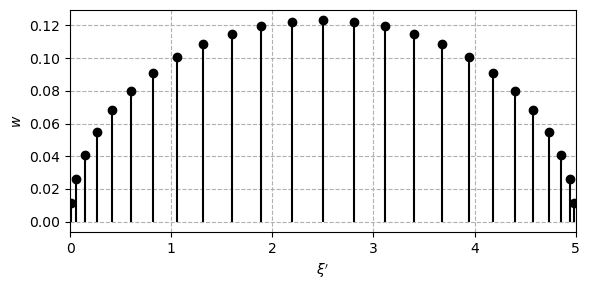

In [4]:
L = 25
a, b = 0, 5
# roots and weights
xi, w = scipy.special.roots_legendre(L)
xi_prime = ((b-a)/2) * xi + ((a+b)/2)
# Figure
plt.figure(figsize = (6,3))
plt.stem(xi_prime, w, 'k', basefmt =" ")
plt.grid(linestyle = '--')
plt.xlim((a, b))
plt.xlabel(r"$\xi^{\prime}$")
plt.ylabel(r"$w$")
plt.tight_layout()

### A. Mid-point sampling

Usada para discretizar um domínio de maneira uniforme. Podemos pensar nos pontos de integração e nos pesos da seguinte forma

\begin{equation}
\xi_{j} = \frac{j-1/2}{L}, \ \ w_j = \frac{1}{L}, \ \ \text{para} \ \ j = 1, 2, \cdots, N,
\end{equation}
em que se nota que os pesos são constantes ao longo do domínio de integração.

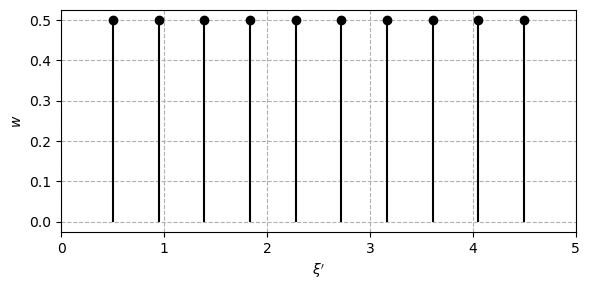

In [5]:
L=10
xi = np.linspace(-1 + 2/L, 1 - 2/L, L) 
xi_prime = ((b-a)/2) * xi + ((a+b)/2)
w = ((b-a)/L) * np.ones(L)

# Figure
plt.figure(figsize = (6,3))
plt.stem(xi_prime, w, 'k', basefmt =" ")
plt.grid(linestyle = '--')
plt.xlim((a, b))
plt.xlabel(r"$\xi^{\prime}$")
plt.ylabel(r"$w$")
plt.tight_layout()

Há muito mais sobre discretização. Mas podemos parar por aqui neste momento e sofisticar as coisas quando necessário. Vamos discutir agora a anatomia específica de alguns problemas inversos.

## Uma nota importante

Vamos compreender alguns problemas que chamaremos de *toy problems*. Eles são versões simplificadas de problemas interessantes que nos ajudam a compreender os algoritmos de regularização, o problema físico em questão e diversos aspectos importantes. Ao mesmo tempo, os *toy problems* fornecem problemas de pequenas dimensões, mais fáceis de analisar, computar e compreender. Além disso, eles nos fornecem uma "solução verdadeira" à qual poderemos comparar as soluções ingênuas e sensatas computadas.

Os formatos finais de $K(s,t)$ e da equação integral na Eq.(5) dependerão da **física** do problema investigado e de sua **dimensionalidade**. Veremos alguns exemplos pra fortalecer nossa intuição.

## Exemplo 1. Medição da densidade

Um dos problemas que vamos investigar em detalhes é medir a densidade, $\rho(x)$, ao longo do espaço (1D), que origina um campo gravitacional medido $g(x')$ a uma certa distância da fonte. Um esquema do problema pode ser visto na Figura 1. Problemas deste tipo ocorrem na geofísica. Temos acesso para medir a aceleração da gravidade ([m/s$^2$]) na superfície, mas queremos determinar a densidade do material ([kg/m$^3$]) a uma profundidade abaixo dela. A ideia pode ser, por exemplo, determinar a densidade das rochas, se há volumes de água ou de gás abaixo da superfície, etc.

<figure style="text-align: center;">
    <img src="\..\figs\gravity.png" width="500" alt="Imagem do conceito do problema problema da gravidade.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 1: Conceito da medição inversa da densidade (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 2.1).
    </figcaption>
</figure>

Vamos reescrever a Eq.(2) para deixá-la mais próxima da notação do problema em mãos.

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x
\end{equation}

O campo gravitacional de uma parte infinitesimalmente pequena com densidade $\rho(x)$ e comprimento $\text{d}x$ é 

\begin{equation}
\rho(x) \text{d} x / r^2,
\end{equation}

em que $r = \sqrt{d^2 + (x' - x)^2}$ é a distância entre o "**ponto fonte**" em $x$ e o "**ponto medido em campo**" em $x'$. A direção do campo gravitacional é no sentido: do "ponto medido em campo" para o "ponto fonte" e, portanto, o valor medido de $\text{d}g(x')$ (causado pelo ponto fonte infinitesimal) é

\begin{equation}
\text{d}g(x') = \text{sin}(\theta)\frac{\rho(x) \text{d}x}{r^2}
\end{equation}
com $\text{sin}(\theta) = d/r$. Assim, o valor total da aceleração da gravidade, $g(x')$, consiste na integral de todos os termos infinitesimais dados na equação anterior, a saber

\begin{equation}
g(x') = \int_{0}^{1}\frac{d}{[d^2+(x' - x)^2]^{3/2}} \rho(x) \text{d}x,
\tag{3}
\end{equation}
que é a integral de Fredholm para o nosso problema específico, com o Kernel dado por 

\begin{equation}
K(x',x) = \frac{d}{[d^2+(x' - x)^2]^{3/2}}.
\tag{4}
\end{equation}

A dimensão física da densidade, neste caso 1D, é $\rho(x)$ [kg/m]. Falta a constante de gravitação universal, $G$ [Nm$^2$/kg$^2$], mas ela não fará muita falta pro nosso propósito, pois atuará apenas escalonando a matriz de sensibilidade do problema. 

### A. O problema direto (forward problem)

Vamos definir funções pra computar a **matriz de sensibilidade**, $\textbf{A}$, e o **termo fonte** (neste caso, o campo de densidades), expresso num vetor $\textbf{x}$, que é a causa do que será de fato medido no vetor $\textbf{b}$. O  **termo fonte** atuará como a solução verdadeira que desejamos computar.

Aqui $\textbf{A}$ será uma matriz quadrada e a discretização será dada pela regra do ponto médio (**mid-point** rule).

Este é o problema direto ou **forward problem**. Ele vai nos permitir **simular** medições e, depois, avaliar aspectos da matriz de sensibilidade e, assim, estudar a viabilidade do problema inverso.

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
$\mathbf{NOTA:}$ Resolver um problema inverso com dados simulados dessa maneira é chamado de $\mathbf{inverse \ crime}$, porque você está simulando medições com um modelo e resolvendo o problema inverso exatamente com o mesmo modelo. No mundo real, o modelo terá simplificações incompatíveis com a realidade. No entanto, fazer o $\mathbf{inverse \ crime}$ tem o seguinte valor: se as coisas falharem, com certeza falharão no mundo real. Se funcionarem, no entanto, há uma boa chance de que funcionem no mundo real.
</div>


In [8]:
def gravity_model(n,a,b,d):
    """ Defines the square matrix A by mid-point sampling
    
    Parameters:
    ------------
    n : int
        order of the model
    a : float
        bottom limit of the Fredholm integral
    b : float
        upper limit of the Fredholm integral
    d : float
        vertical distance from the source line (x') to measurement line (x)

    Returns:
    ------------
    A : numpy ndArray
        n x n real sensing matrix
    """
    dx = 1/n
    dxl = (b-a)/n
    x = dx * (np.arange(n) + 0.5) 
    xl = a + dxl * (np.arange(n) + 0.5) 
    X,XL = np.meshgrid(x,xl)
    A = dx * (d/(d**2 + (X-XL)**2)**(3/2)) # Eq (4)
    return A

def density_pieciwise(n):
    """ Piecewise source function
    
    Defines a function of order n for which the first 1/3 of the source points are 2, and the rest are 1.
    
    Parameters:
    ------------
    n : int
        order of the model

    Returns:
    ------------
    rhox : numpy 1dArray
        pieciwise source term
    """
    nn = int(n/3)
    rhox = np.ones(n)
    rhox[:nn] = 2
    return rhox

### B. Medição vs. distância

Investiguemos o que acontece com a aceleração da gravidade medida $g(x)$, ao aumentarmos a distância de medição $d$ do termo fonte.

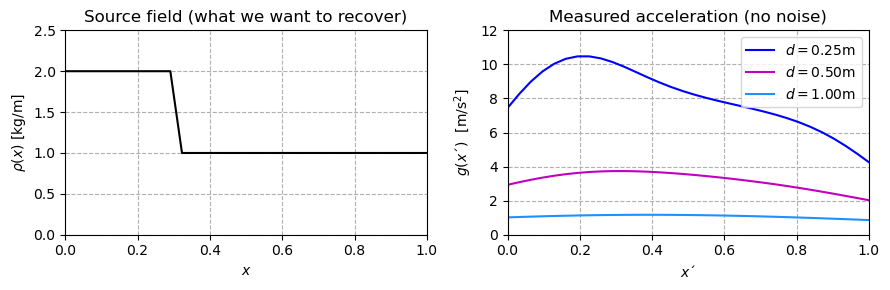

In [9]:
n = 32 # order
a = 0 # bottom limit
b = 1 # upper limit
# measured distances
distances = [0.25, 0.5, 1]
# source function
rhox = density_pieciwise(n = n)
# sampling measurement points
x = np.linspace(a, b, n)

# measured gravity (fake data with no noise at all)
g_vs_d = []
for d in distances:
    A = gravity_model(n = n,a = a,b = b,d = d) # matrix
    g_vs_d.append(A @ rhox) # b = A@x (forward problem)

    
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, 'k')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((0, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (what we want to recover)')
axs[1].plot(x, g_vs_d[0], label = r'$d = 0.25$m', color = 'b')
axs[1].plot(x, g_vs_d[1], label = r'$d = 0.50$m', color = 'm')
axs[1].plot(x, g_vs_d[2], label = r'$d = 1.00$m', color = 'dodgerblue')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 12))
axs[1].legend(loc = 'upper right')
axs[1].grid(True)
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

## O que você observa?
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Quanto **mais longe** medirmos da fonte (origem do fenômeno), **menor** é a amplitude da grandeza medida (consequência).
- Aparentemente, a grandeza medida também se torna **mais suave** ou com menor variação ao longo do espaço.

  
</details>

Nós podemos ir além a calcular a transformada de Fourier do termo fonte, que é dado por

\begin{equation}
\rho(x) = 
\begin{cases}
2  \ \ \ \text{p/} \ \ \ 0 \leq x < 1/3 \\
1  \ \ \ \text{caso contrário} 
\end{cases}
\end{equation}

A transformada espacial de Fourier (TEF) é

\begin{equation}
\tilde{\rho}(k) = \int_{-\infty}^{\infty}\rho(x) \text{e}^{-\text{j} k x} \text{d}x
\end{equation}
em que $k$ é a frequência espacial (ou o número de onda) em [rad/m]. Assim, a TEF deste caso específico resulta em:

\begin{equation}
\rho(k) = \int_{0}^{1/3}2 \text{e}^{-\text{j} k x} \text{d}x + \int_{1/3}^{1}1 \text{e}^{-\text{j} k x} \text{d}x
\end{equation}

\begin{equation}
\rho(k) = -\frac{1}{\text{j}k}\left[\text{e}^{-\text{j} k}+ \text{e}^{-\text{j} k/3}-2\right]
\end{equation}

Podemos plotar a magnitude desta função e notar como o termo fonte possui diversas componentes de baixa e alta frequência espacial.

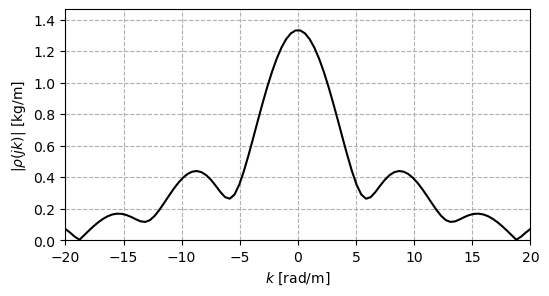

In [10]:
k = np.linspace(-20, 20, 100)
Rhow = (-1/(1j*k))*(np.exp(-1j*k)+np.exp(-1j*k/3)-2)

plt.figure(figsize = (6,3))
plt.plot(k, np.abs(Rhow), 'k')
plt.grid(linestyle = '--')
plt.xlim((k[0], k[-1]))
plt.ylim((0, 1.1*np.abs(Rhow).max()))
plt.xlabel(r'$k$ [rad/m]')
plt.ylabel(r'$|\rho(jk)|$ [kg/m]');

### C. Influência da frequência espacial no dado medido

**Note:** Embora a **função medida** seja suave, o termo fonte é uma função com uma **descontinuidade** no espaço. Por isso, é composto por muitos componentes de **alta frequência espacial**. São essas frequências que causam variabilidade no dado medido e, quanto maior a frequência espacial, maior a variação. No entanto, as **frequências mais altas** tendem a **decair** mais rapidamente à medida que a distância aumenta. Assim, ao medir mais longe da fonte, você medirá menos componentes de alta frequência e, portanto, o dado medido será mais suave do que a uma distância menor.

Vamos investigar um **termo fonte** com apenas uma frequência. Podemos variar os falores de $f_{\rho}$. O novo termo fonte é dado por

\begin{equation}
\rho(x) = \text{sin}(2\pi f_{\rho} x).
\end{equation}

A suavização da função medida pode ser expressa pelo lema de Riemann–Lebesgue, da seguinte forma:

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x \rightarrow 0, \ \ \ \ \ \ \ \ \text{para} \ \ \ \ \ \ f_p \rightarrow \infty.
\end{equation}

Assim, **componentes de alta frequência espacial** tendem a **decair abruptamente** a partir da fonte.


<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 700px;">

Note então que a amplitude e variabilidade do fenômeno medido é menor para:

- maiores distâncias (da simulação anterior)
- maiores frequências espaciais no fenômeno de origem

</div>

In [11]:
def density_sin(x, fp):
    """ Sinusoidal source function
    
    Defines a function or order len(x) for a sinusoidal source function.
    
    Parameters:
    -----------
    x : 1dArray
        measured coordinates
    fp : float
        spatial frequency of the phenomenon
    Returns:
    ------------
    rhox : numpy 1dArray
        sinusoidal source term
    """
    rhox = np.sin(2*np.pi*fp*x)
    return rhox

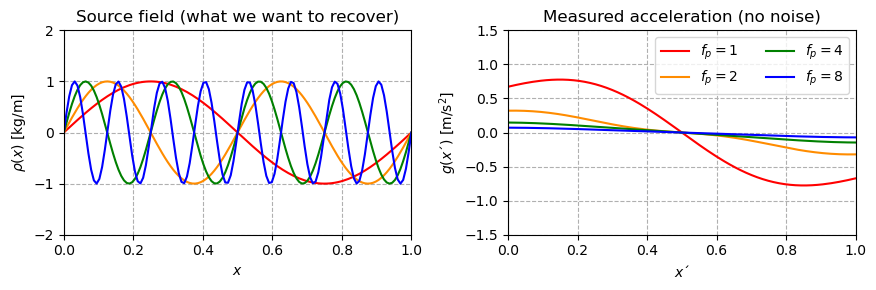

In [13]:
n = 128 # order
a = 0 # bottom limit
b = 1 # upper limit
d = 0.5

# measured coordinates
x = np.linspace(a, b, n)

# frequencies to be investigated
fp = [1, 2, 4, 8]

# model
A = gravity_model(n = n,a = a,b = b,d = d)

rhox_vs_fp = [] # source functions
g_vs_fp = [] # measured data as a function of fp
for p in fp:
    rhox = density_sin(x, p)
    rhox_vs_fp.append(rhox)
    g_vs_fp.append(A @ rhox)

    
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox_vs_fp[0], color = 'r')
axs[0].plot(x, rhox_vs_fp[1], color = 'darkorange')
axs[0].plot(x, rhox_vs_fp[2], color = 'g')
axs[0].plot(x, rhox_vs_fp[3], color = 'b')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((-2, 2))
axs[0].grid(linestyle = '--')
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (what we want to recover)')
axs[1].plot(x, g_vs_fp[0], label = r'$f_p = 1$', color = 'r')
axs[1].plot(x, g_vs_fp[1], label = r'$f_p = 2$', color = 'darkorange')
axs[1].plot(x, g_vs_fp[2], label = r'$f_p = 4$', color = 'g')
axs[1].plot(x, g_vs_fp[3], label = r'$f_p = 8$', color = 'b')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((-1.5, 1.5))
axs[1].legend(loc = 'upper right', ncols = 2)
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$ [m/s$^2$]')
axs[1].set_title(r'Measured acceleration (no noise)')
plt.tight_layout()

### Pergunta: num problema inverso, qual é o problema com as altas frequências?

**DICA** Considere o efeito do ruído no que foi discutido até aqui.

<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Menores amplitudes são causadas por: **maiores distâncias** de medição e **maiores frequências espaciais** no fenômeno de origem.
- As amplitudes menores em $g(x^{'})$ (associadas às maiores frequências) tendem a ser **mais corrompidas por ruído**;
- Ao tentar inferir componentes de alta frequência espacial em $\rho(x)$, a partir de dados medidos em $g(x^{'})$ haverá **amplificação**.
- Se não formos cautelosos, vamos acabar amplificando ruído e condenando nossa solução.
 
</details>

## Exemplo 2. Medição de temperatura vs. tempo

Suponha que você precise medir a temperatura de uma barra (por simplicidade, semi-infinita e 1D). A dificuldade aqui é que, em $x=0$, as temperaturas tendem a ser excessivamente elevadas, o que impede a medição direta. Então, a solução é medir a temperatura em $x=L$ e resolver o problema inverso para recuperar a temperatura na fonte em $x=0$. A Figura 2 ilustra o problema de forma esquemática.

<figure style="text-align: center;">
    <img src="\..\figs\bar_temp.png" width="500" alt="Imagem do conceito do problema problema de calor.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figure 2: Conceito da medição inversa da temperatura em uma barra.
    </figcaption>
</figure>

A equação integral que rege tal problema é dada por (sem entrar nos detalhes de derivação)

\begin{equation}
T(x, t) = \int_{0}^{t}K(x, t-\tau) u(\tau) \text{d}\tau,
\tag{5}
\end{equation}
que $x$ é o local fixo no espaço onde tomamos medições de temperatura em função do tempo, $t$; $T(x, t)$ é a temperatura medida em $x$, em função do tempo, e $u(t)$ é o termo fonte de temperatura que gostaríamos de recuperar. A equação integral na Eq. (5) é conhecida como integral de Volterra (similar a integral de Fredholm). Para uma barra 1D e infinita, o Kernel é dado por 

\begin{equation}
K(x,t) = \frac{x}{2\sqrt{\pi \alpha} t^{3/2}} \text{exp}(-\frac{x^2}{4\alpha t}),
\tag{6}
\end{equation}
em que $\alpha$ o coeficiente de difusão térmica. 

Podemos estudar brevemente o problema para verificar as afirmações feitas no problema de gravidade. Vamos avaliar o que ocorre quando medimos a temperatura mais e mais longe da fonte e os efeitos de suavização das componentes de alta frequência (neste caso temporal) para dois tipos de fonte:

- Um pulso retangular
- Temperatura com flutuação aleatória

In [14]:
def heat_kernel(t, L=1.0, alpha = 1.0):
    """
    Boundary Green's function for a semi-infinite rod.

    Parameters
    ----------
    t : numpy1dArray
        Time lag in (s), t > 0.
    L : float
       measurement location.
    alpha: float
        thermal diffusivity (default set to 1.0 for dimensionless).

    Returns
    -------
    K : ndarray
        Kernel evaluated at each time lag.
    """
    K = np.zeros_like(t)
    mask = t > 0
    K[mask] = (L/(2 * np.sqrt(np.pi * alpha) * t[mask]**1.5))*np.exp(-L**2 / (4 * alpha * t[mask]))
    return K

def heat_forward_matrix(tmax, fs, L=1.0, alpha= 1.0):
    """
    Construct the sensing matrix

    Parameters
    ----------
    tmax : float
        maximum time measurement instant
    fs : int
        sampling rate of measurement
    L : float
        measurement location
    alpha: float
        thermal diffusivity (default set to 1.0 for dimensionless)        
    """
    t = np.arange(0, tmax, 1/fs)
    dt = t[1] - t[0]
    n = len(t)
    G = np.zeros((n, n))
    for i in range(n):
        tau = t[i] - t[:i+1]
        G[i, :i+1] = heat_kernel(tau, L, alpha)
    return G * dt, t

def heat_square_pulse(t, tinit = 1, tend = 2, Tsource = 200):
    """ Square pulse of temperature.

    Parameters
    ----------
    t : numpy1dArray
        Time in (s), t > 0
    tinit : float
        initial time instant of pulse
    tend : float
        final time instant of pulse
    Tsource : float
        source temperature in K
    """
    u = np.zeros_like(t)
    u[(t > tinit) & (t < tend)] = Tsource
    return u

def heat_random(t, mean_temp = 300, std_temp = 100):
    u = np.random.normal(loc = mean_temp, scale = std_temp, size = len(t))
    return u
    

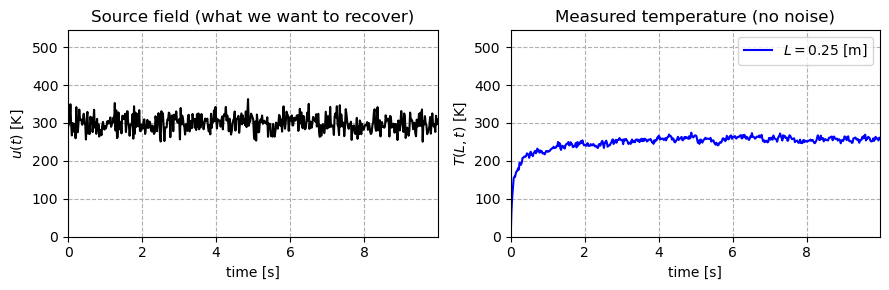

In [18]:
t_max = 10
L = 0.25
G, time = heat_forward_matrix(tmax = t_max, fs = 50 , L=L, alpha=1.0)

tinit, tend = 1, 4 # temprature pulse start and end
#u = heat_square_pulse(time, tinit, tend, Tsource = 200)
u = heat_random(time, mean_temp = 300, std_temp = 20)
#u = heat_random(time, mean_temp = 300, std_temp = 20) * heat_square_pulse(time, tinit, tend, Tsource = 1)
Tl = G @ u # measured temp

# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(time, u, 'k')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, time[-1]))
axs[0].set_ylim((0, 1.5*u.max()))
axs[0].set_xlabel(r'time [s]')
axs[0].set_ylabel(r'$u(t)$ [K]')
axs[0].set_title(r'Source field (what we want to recover)')
axs[1].plot(time, Tl, label = r'$L = ${} [m]'.format(L), color = 'b')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, time[-1]))
axs[1].set_ylim((0, 1.5*u.max()))
axs[1].legend(loc = 'upper right')
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'time [s]')
axs[1].set_ylabel(r'$T(L,t)$ [K]')
axs[1].set_title(r'Measured temperature (no noise)')
plt.tight_layout()

## Exemplo 3. Difração sonora

A medição de um absorvedor ou difusor acústico é um tema complexo e ocorre basicamente da seguinte maneira: 

(i) - excitamos o campo acústico com uma fonte sonora colocada em frente ao aparato que queremos caracterizar; 
(ii) - varremos o espaço ao redor do aparato com um microfone; 
(iii) - formulamos um problema inverso para separar o campo sonoro incidente do difratado. 

Veja a Figura 3, que ilustra um experimento típico. 

<figure style="text-align: center;">
    <img src="\..\figs\Experimento montado.jpg" width="350" alt="Imagem da medição de um difusor acústico.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 3: Conceito da medição inversa da difração 3D de um objeto.
    </figcaption>
</figure>

A pressão sonora difratada (ou espalhada - *scattered*) por um objeto, medida em uma dada frequência $f$ [Hz], é modelada pela equação integral de Helmholtz, dada por

\begin{equation}
p_s(\mathbf{r}) = \int_{\Lambda}\left[p(\mathbf{r}_\Lambda)\frac{\partial G(\mathbf{r}, \mathbf{r}_\Lambda)}{\partial \vec{n}} -j \rho c k_0 v(\mathbf{r}_\Lambda)G(\mathbf{r}, \mathbf{r}_\Lambda)\right] d\Lambda ,
\tag{7}
\end{equation}
em que $\rho$ e $c$ são a densidade e a velocidade do som no meio de propagação, respectivamente (*e.g.* para o ar $\rho \approx 1.2$ [kg/m$^3$] e $c = 340$ [m/s]); $k_0 = 2\pi f/c$ [rad/m] é a magnitude do número de onda na frequência $f$; $\mathbf{r}$ representa um ponto de medição no espaço e $\mathbf{r}_\Lambda$ um ponto sobre a superfície do aparato difrator. Este caso parece mais complicado, porque há 2 kernels, dados pela função de Green, $G(\mathbf{r}, \mathbf{r}_\Lambda)$ e sua derivada com respeito à normal. Em 3D, tal função de Green é

\begin{equation}
G(\mathbf{r}, \mathbf{r}_\Lambda) = \frac{e^{-jk_0|\bf{r}-\bf{r}_\Lambda|}}{|\bf{r}-\bf{r}_\Lambda|}
\tag{8}
\end{equation}
e sua derivada é

\begin{equation}
\frac{\partial G(\mathbf{r}, \mathbf{r}_\Lambda)}{\partial \vec{n}} = \frac{-jk_0(z-z_\Lambda)}{4\pi |\bf{r}-\bf{r}_\Lambda|} \frac{e^{-jk_0|\bf{r}-\bf{r}_\Lambda|}}{|\bf{r}-\bf{r}_\Lambda|}\left[1+\frac{1}{jk_0|\bf{r}-\bf{r}_\Lambda|}\right].
\tag{9}
\end{equation}

Consequentemente, temos 2 termos fonte a determinar: a pressão sobre a superfície, $p(\mathbf{r}_\Lambda)$, e a velocidade sobre a superfície, $v(\mathbf{r}_\Lambda)$.

O ponto principal aqui não é compreender o problema da difração sonora agora. Mas, sim, a **conexão** deste problema com os outros.

# 3. Kernel, Função de Green e convolução

Em todos os problemas formulados, o que chamamos de Kernel também é conhecido como a função de Green do problema físico em questão. Esta função é responsável por **impor as características do modelo físico** ao termo **fonte**, e o resultado é o que se **mede** (numa situação sem ruído, pelo menos). No nosso esquema de problemas inversos, dado na Figura 4, o sistema modelado pela função de Green, transforma o sinal de entrada numa saída que conseguimos medir. 

<figure style="text-align: center;">
    <img src="\..\figs\probinv_conceito.png" width="500" alt="Imagem do conceito do problema inverso.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 4: Conceito do problema inverso (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 1.3).
    </figcaption>
</figure>

Esta transformação é modelada por integrais do tipo de Fredholm, uma operação também conhecida, na área de processamento de sinais, como **convolução**. Você pode ver a operação em uma analogia a um grande filme.

<figure style="text-align: center;">
    <img src="\..\figs\AnakinSkywalker.jpg" width="200" alt="Imagem de Anakyn Skywalker.">
    <img src="\..\figs\darth-vader-suit.jpg" width="200" alt="Imagem da roupa de Darth Vader.">
    <img src="\..\figs\darth-vader.jpg" width="200" alt="Imagem de Darth Vader.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 5: (a) input = Anakyn Skywalker, (b) model = representado pelo traje e histórico do personagem, (c) output = Darth Vader - o novo personagem com nova personalidade.
    </figcaption>
</figure>

# A história até aqui

Quando conhecemos a medição (com algum erro e incerteza) e o modelo (potencialmente com simplificações), podemos tentar recuperar o termo fonte. Este processo também pode ser chamado de **deconvolução**, já que o problema direto (*forward model*) é chamado de **convolução**.

Nós já vimos como isto pode ser um problema difícil em sistemas de pequenas dimensões ($2 \times 2$ ou $3 \times 2$, $1 \times 2$, etc). A solução **ingênua**, dada por $\tilde{\mathbf{x}} = \mathbf{A}^{-1}\mathbf{b}$, falha miseravelmente devido ao ruído.

A partir daqui, vamos construir um ferramental pra nos ajudar a analisar problemas maiores, como os que já mostramos até aqui. A má notícia é que nestes casos, a solução **ingênua** falha mesmo por erros de arredondamento. 

A boa notícia é que o problema tem solução (ou melhor, aproximação). Ao nosso resgate vem o **SVD** (*Singular Value Decomposition* ou decomposição em valores singulares) e as técnicas de regularização.